# Average call rate pass-through after expected vs. surprise repo rate changes

**Question.** After an RBI repo rate change, does the call money rate follow the change more or less in the first few days and weeks when the change was **expected** than when it was a **surprise**?

**Method**
1. For each repo rate decision, compute the **average pass-through** over the first *N* trading days after the decision, for *N* = 1, 3, 7, 11, 17 and 23:

$$
\text{avg pass-through}_N = \frac{\text{mean call rate over days } 1 \ldots N \;-\; \text{mean call rate over days } -5 \ldots -1}{\text{repo rate change}}
$$

   A value of **1.0** means that, on average over those *N* days, the call rate moved by exactly as much as the repo rate. **0.5** means it moved halfway.

2. For each window, compare the **average for expected decisions** with the **average for surprise decisions** using **Welch's t-test**, which tests whether two averages differ and doesn't assume both groups are equally spread out.

Day 0, the decision day itself, is left out because the decision is announced partway through the trading day.

In [ ]:
import pandas as pd, numpy as np
from scipy import stats
import matplotlib.pyplot as plt

REPO_FILE  = "rbi_repo_rate_decision.xlsx"                              # change to your path
DAILY_FILE = "r50_daily_weighted_average_call_notice_money_rates.csv"   # change to your path

WINDOWS = [1, 3, 7, 11, 17, 23]   # trading days after the decision
EXCLUDE_EXTREME = True            # drop events where the call rate moved > 5x the repo change

## 1. Repo rate decisions and labels

Each decision is labelled **expected (1)** or **surprise (0)**:
- **From 2013:** by the market consensus forecast in the data.
- **Off-cycle moves** (between scheduled meetings): always surprises.
- **Scheduled decisions before 2013** (no forecast in the data): by judgement from news coverage at the time. The reason is noted next to each date.

In [ ]:
repo = pd.read_excel(REPO_FILE, sheet_name="Sheet1")
repo["date"] = pd.to_datetime(repo["Date"], format="%b %d, %Y")
repo["rate"] = np.where(repo["Actual"] < 1, repo["Actual"] * 100, repo["Actual"]).round(2)
repo["consensus"] = pd.to_numeric(repo["Consensus"], errors="coerce") * 100
repo = repo.sort_values("consensus", na_position="last").drop_duplicates("date").sort_values("date")   # keep the row with a forecast
repo["change"] = repo["rate"].diff().round(2)

dec = repo[(repo["change"].fillna(0) != 0) & (repo["date"] >= "2005-01-01")][["date", "change", "rate", "consensus"]]
missing = pd.DataFrame({"date": pd.to_datetime(["2006-10-31", "2007-01-31", "2007-03-30", "2008-06-11",
                                                "2008-06-24", "2008-07-29", "2008-10-20", "2008-11-03"]),
                        "change": [0.25, 0.25, 0.25, 0.25, 0.50, 0.50, -1.00, -0.50]})
dec = pd.concat([dec, missing]).sort_values("date").reset_index(drop=True)

OFF_CYCLE = pd.to_datetime(["2006-06-09", "2007-03-30", "2008-06-11", "2008-06-24", "2008-10-20",
                            "2008-11-03", "2008-12-08", "2009-01-02", "2009-03-04", "2010-03-22",
                            "2010-07-05", "2015-01-15", "2015-03-04", "2020-03-27", "2020-05-22",
                            "2022-05-04"])

JUDGED = {                     # 1 = expected (direction AND size anticipated), 0 = surprise
    "2005-11-09": 1,  # 25 bp hike in line with a signalled tightening cycle
    "2006-01-24": 0,  # views split; leading commentary expected no hike before the Budget
    "2006-07-25": 1,  # 25 bp hike, market reaction "no surprises here"
    "2006-10-31": 1,  # 25 bp hike during an ongoing tightening cycle
    "2007-01-31": 1,  # 25 bp hike with inflation above RBI's comfort zone
    "2008-07-29": 0,  # 50 bp hike, larger than the 25 bp many expected
    "2009-04-21": 0,  # 25 bp cut that "surprised the Street"
    "2010-04-21": 1,  # in line with consensus
    "2010-07-27": 0,  # reverse repo raised 50 bp, double the 25 bp expected
    "2010-09-16": 0,  # reverse repo raised 50 bp, more than the 25 bp expected
    "2010-11-02": 1, "2011-01-25": 1, "2011-03-17": 1,      # 25 bp hikes, in line with consensus
    "2011-05-03": 0,  # 50 bp hike; bankers had predicted 25 bp
    "2011-06-16": 1,  # in line with consensus
    "2011-07-26": 0,  # 50 bp hike; "RBI surprises with 50-bps rise"
    "2011-09-16": 1, "2011-10-28": 1,                       # 25 bp hikes, in line with consensus
    "2012-04-17": 0,  # 50 bp cut; market expected 25 bp
    "2013-01-29": 1,  # 25 bp cut, in line with consensus
}

forecast = (dec["rate"].round(2) == dec["consensus"].round(2)).astype(float).where(dec["consensus"].notna())
judged = dec["date"].dt.strftime("%Y-%m-%d").map(JUDGED)
dec["expected"] = forecast.fillna(judged)
dec.loc[dec["date"].isin(OFF_CYCLE), "expected"] = 0
dec["expected"] = dec["expected"].fillna(0).astype(int)
dec["has_forecast"] = dec["consensus"].notna() | dec["date"].isin(OFF_CYCLE)

dec.groupby(dec["date"].dt.year >= 2013)["expected"].value_counts().unstack()

expected,0,1
date,,
False,19,11
True,16,17


## 2. Average pass-through in each window

An event is **clean** if no other repo change follows within the longest window (23 trading days), so the measured reaction belongs to one decision only.

In [ ]:
daily = pd.read_csv(DAILY_FILE)
daily["date"] = pd.to_datetime(daily["c1"].astype(str).str.strip(), format="%d-%b-%y", errors="coerce")
wacr = (daily.assign(wacr=pd.to_numeric(daily["c4"], errors="coerce"))
             .dropna(subset=["date", "wacr"]).drop_duplicates("date")
             .set_index("date")["wacr"].sort_index())
days = wacr.index

rows = []
for _, r in dec.iterrows():
    i0 = days.searchsorted(r["date"])                        # day 0 = first trading day on/after decision
    if i0 < 5 or i0 + max(WINDOWS) >= len(days):
        continue
    base = wacr.iloc[i0 - 5:i0].mean()
    row = {"date": r["date"], "i0": i0, "change": r["change"],
           "expected": r["expected"], "has_forecast": r["has_forecast"]}
    for n in WINDOWS:
        row[n] = (wacr.iloc[i0 + 1:i0 + 1 + n].mean() - base) / r["change"]
    rows.append(row)
ev = pd.DataFrame(rows)

gap = ev["i0"].shift(-1) - ev["i0"]
ev = ev[gap.isna() | (gap > max(WINDOWS))]                     # keep clean events only

extreme = ev[WINDOWS].abs().max(axis=1) > 5
print("Extreme events (call rate moved > 5x the repo change):")
print(ev.loc[extreme, ["date", "change", "expected"]].to_string(index=False))
if EXCLUDE_EXTREME:
    ev = ev[~extreme]

print(f"\nEvents used: {len(ev)}  (expected {ev['expected'].sum()}, surprise {(ev['expected'] == 0).sum()})")

Extreme events (call rate moved > 5x the repo change):
      date  change  expected
2007-03-30    0.25         0
2008-11-03   -0.50         0
2013-09-20    0.25         0

Events used: 56  (expected 27, surprise 29)


## 3. Test: is the average different in each window?

For every window the table shows the average for each group, the difference (expected − surprise) with its 95% confidence interval, and the Welch t-test p-value. **p < 0.05** means the difference is unlikely to be chance.

The test is run on two samples:
- **2005–2025:** all decisions, including judged labels before 2013.
- **2013–2025:** only decisions with a real market forecast (or off-cycle).

In [ ]:
def window_test(data):
    out = []
    for n in WINDOWS:
        e, s = data.loc[data["expected"] == 1, n], data.loc[data["expected"] == 0, n]
        t = stats.ttest_ind(e, s, equal_var=False)
        ci = t.confidence_interval(0.95)
        out.append({"window (days)": n, "n_expected": len(e), "n_surprise": len(s),
                    "avg_expected": e.mean(), "avg_surprise": s.mean(),
                    "difference": e.mean() - s.mean(), "ci_low": ci.low, "ci_high": ci.high,
                    "p_value": t.pvalue, "significant": "yes" if t.pvalue < 0.05 else "no"})
    return pd.DataFrame(out).set_index("window (days)")

samples = {"2005–2025": ev,
           "2013–2025 (real forecasts)": ev[ev["has_forecast"] & (ev["date"] >= "2013-01-01")]}
results = {name: window_test(data) for name, data in samples.items()}

for name, table in results.items():
    print(f"\n{name}")
    display(table.round(3))


2005–2025


,n_expected,n_surprise,avg_expected,avg_surprise,difference,ci_low,ci_high,p_value,significant
window (days),,,,,,,,,
1,27,29,1.083,0.841,0.242,-0.345,0.830,0.411,no
3,27,29,0.989,0.851,0.138,-0.443,0.718,0.636,no
7,27,29,0.983,0.801,0.182,-0.364,0.727,0.507,no
11,27,29,0.936,0.739,0.197,-0.335,0.729,0.460,no
17,27,29,0.884,0.788,0.096,-0.397,0.589,0.697,no
23,27,29,0.841,0.748,0.092,-0.385,0.570,0.699,no



2013–2025 (real forecasts)


,n_expected,n_surprise,avg_expected,avg_surprise,difference,ci_low,ci_high,p_value,significant
window (days),,,,,,,,,
1,15,15,1.449,0.668,0.781,0.156,1.407,0.017,yes
3,15,15,1.199,0.902,0.297,-0.297,0.890,0.312,no
7,15,15,0.968,0.678,0.290,-0.431,1.012,0.411,no
11,15,15,1.061,0.718,0.343,-0.307,0.994,0.286,no
17,15,15,1.131,0.839,0.292,-0.318,0.903,0.333,no
23,15,15,1.172,0.747,0.425,-0.170,1.020,0.154,no


## 4. Plot

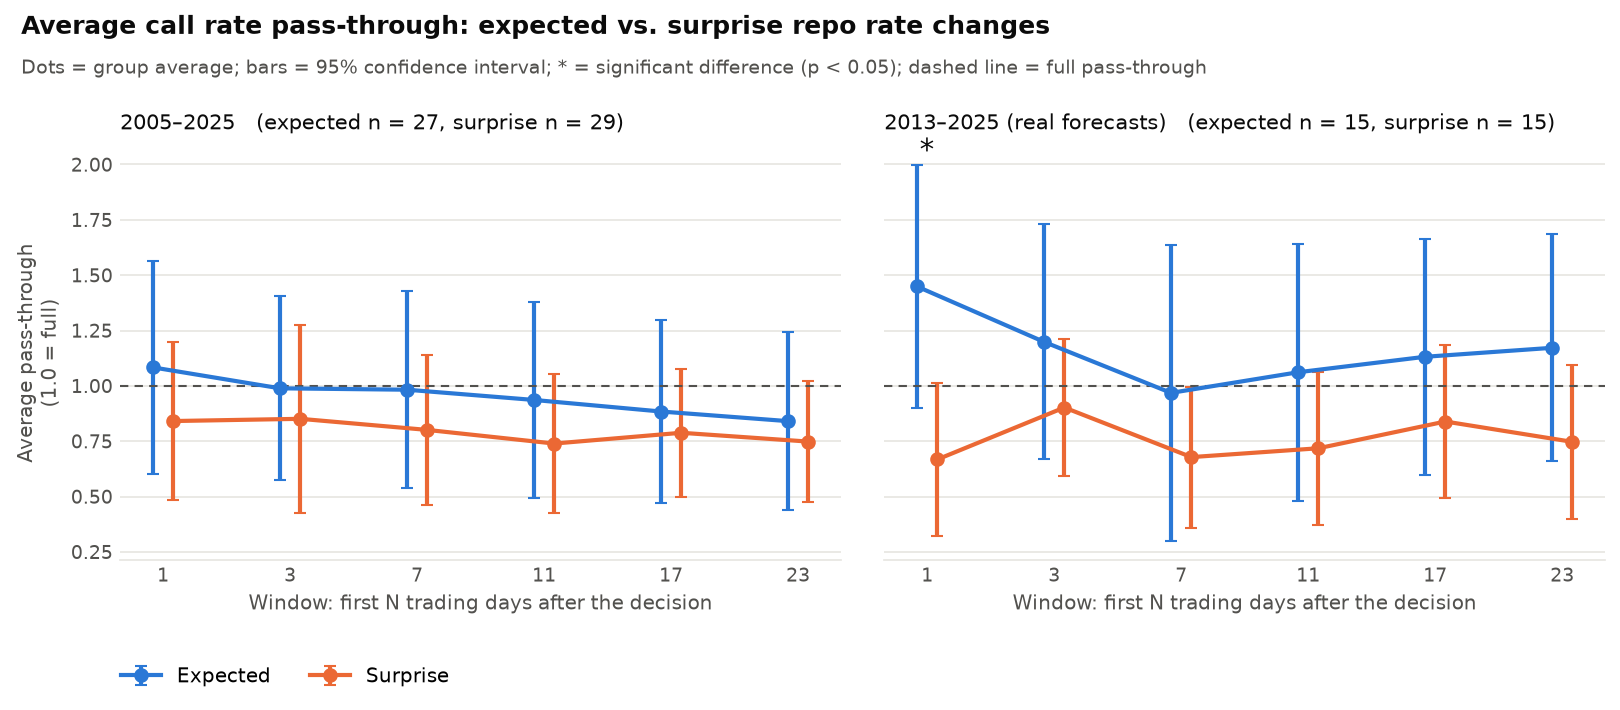

In [ ]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0"
x = np.arange(len(WINDOWS))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), dpi=150, sharey=True)
for ax, (name, data) in zip(axes, samples.items()):
    for label, color, name_g, shift in [(1, BLUE, "Expected", -0.08), (0, ORANGE, "Surprise", 0.08)]:
        g = data[data["expected"] == label]
        mean = g[WINDOWS].mean()
        half = g[WINDOWS].sem() * stats.t.ppf(0.975, len(g) - 1)
        ax.errorbar(x + shift, mean, yerr=half, color=color, marker="o", markersize=6,
                    linewidth=2, capsize=3, label=name_g)
    for i, p in enumerate(results[name]["p_value"]):
        if p < 0.05:
            ax.text(x[i], 0.97, "*", transform=ax.get_xaxis_transform(), ha="center",
                    fontsize=14, color=INK)
    ax.axhline(1, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.set_xticks(x, [str(n) for n in WINDOWS])
    ax.set_xlabel("Window: first N trading days after the decision", fontsize=9.5, color=MUTED)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)

axes[0].set_ylabel("Average pass-through\n(1.0 = full)", fontsize=9.5, color=MUTED)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, ["Expected", "Surprise"], frameon=False, fontsize=9.5, ncol=2,
           loc="lower left", bbox_to_anchor=(0.07, -0.01))
for ax, (name, data) in zip(axes, samples.items()):
    n_e, n_s = int(data["expected"].sum()), int((data["expected"] == 0).sum())
    ax.set_title(f"{name}   (expected n = {n_e}, surprise n = {n_s})", loc="left", fontsize=10, color=INK, pad=8)
fig.suptitle("Average call rate pass-through: expected vs. surprise repo rate changes",
             x=0.02, y=0.99, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.text(0.02, 0.905, "Dots = group average; bars = 95% confidence interval; * = significant difference (p < 0.05); dashed line = full pass-through",
         ha="left", fontsize=9, color=MUTED)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.2, top=0.80, wspace=0.06)
plt.show()

## How to read the results

- **Dots above 1.0:** the call rate moved *more* than the repo rate (overshoot). **Below 1.0:** it moved less, or hadn't caught up yet.
- **A significant difference in short windows only** (1–3 days): one group reacts faster, but both end up in the same place.
- **A significant difference in long windows** (17–23 days): the groups settle at different levels.
- **No stars:** expected and surprise changes pass through by the same average amount in every window.
- **Agreement across both samples** makes a result much more convincing, because the 2013–2025 sample uses real forecasts only.
- **Extreme events:** set `EXCLUDE_EXTREME = False` at the top to see how much they change the answer.

In [ ]:
# ---------- LAF: money injected and absorbed by the RBI, counted until repaid (Rs crore) ----------
import warnings; warnings.filterwarnings("ignore")         # harmless Excel-format warnings
LAF_FILE = "Daily_LAF_Operation.xlsx"     # change to your path

L = pd.read_excel(LAF_FILE, header=None, skiprows=6).iloc[:, [1, 2, 6, 11, 13, 17, 19, 23]]
L.columns = ["date", "fix_days", "fix_repo", "fix_rrepo", "var_repo_days", "var_repo", "var_rrepo_days", "var_rrepo"]
L["date"] = pd.to_datetime(L["date"], errors="coerce")
L = L.dropna(subset=["date"])
L.iloc[:, 1:] = L.iloc[:, 1:].apply(pd.to_numeric, errors="coerce")
old = L["date"] < "2004-10-29"                                   # before Oct 2004, "repo" meant absorption
L.loc[old, ["fix_repo", "fix_rrepo"]] = L.loc[old, ["fix_rrepo", "fix_repo"]].values

def outstanding(amount, tenor):
    end = L["date"] + pd.to_timedelta(tenor.fillna(1).clip(lower=1), unit="D")
    flow = (amount.fillna(0).groupby(L["date"]).sum()
            .sub(amount.fillna(0).groupby(end).sum(), fill_value=0))
    return flow.resample("D").sum().cumsum()

injected = outstanding(L["fix_repo"],  L["fix_days"]) .add(outstanding(L["var_repo"],  L["var_repo_days"]),  fill_value=0)
absorbed = outstanding(L["fix_rrepo"], L["fix_days"]) .add(outstanding(L["var_rrepo"], L["var_rrepo_days"]), fill_value=0)

In [ ]:
# ---------- Extra money absorbed (hikes) / injected (cuts) after each decision, per 25 bp ----------
LAF_WINDOWS = [1, 3, 5, 7, 11, 17, 23]
HIKE_END = "2022-03-31"                  # absorption through the SDF (from Apr 2022) is not in the LAF file

def laf_effect(series, date, change, n):
    i0 = days.searchsorted(date)
    before = series.reindex(days[i0 - 5:i0]).mean()              # 5 trading days before
    after = series.reindex(days[i0 + 1:i0 + 1 + n]).mean()       # first n trading days after
    return (after - before) / (abs(change) / 0.25)

d = dec.assign(i0=days.searchsorted(dec["date"]))
gap = d["i0"].shift(-1) - d["i0"]
d = d[(gap.isna() | (gap > max(LAF_WINDOWS))) & (d["i0"] >= 5) & (d["i0"] + max(LAF_WINDOWS) < len(days))]

hikes = d[(d["change"] > 0) & (d["date"] <= HIKE_END)].copy()
cuts = d[d["change"] < 0].copy()
for n in LAF_WINDOWS:
    hikes[n] = [laf_effect(absorbed, r.date, r.change, n) for r in hikes.itertuples()]
    cuts[n] = [laf_effect(injected, r.date, r.change, n) for r in cuts.itertuples()]

def laf_test(data):
    rows = []
    for n in LAF_WINDOWS:
        s, e = data.loc[data["expected"] == 0, n], data.loc[data["expected"] == 1, n]
        p = stats.ttest_ind(s, e, equal_var=False).pvalue
        rows.append({"window": n, "n_surprise": len(s), "n_expected": len(e),
                     "avg_surprise": s.mean(), "avg_expected": e.mean(),
                     "p_value": p, "significant": "yes" if p < 0.05 else "no"})
    return pd.DataFrame(rows).set_index("window")

laf = {"Hikes: extra money absorbed (2005 – Mar 2022)": hikes,
       "Cuts: extra money injected (2005–2025)": cuts}
laf_tables = {name: laf_test(data) for name, data in laf.items()}
for name, table in laf_tables.items():
    print(f"\n{name}   (Rs crore per 25 bp, vs. 5 days before)")
    display(table.round(3))


Hikes: extra money absorbed (2005 – Mar 2022)   (Rs crore per 25 bp, vs. 5 days before)


,n_surprise,n_expected,avg_surprise,avg_expected,p_value,significant
window,,,,,,
1,14,12,1969.407,9069.233,0.371,no
3,14,12,762.026,9305.539,0.286,no
5,14,12,-410.593,7547.617,0.234,no
7,14,12,-1638.853,6257.102,0.163,no
11,14,12,-3455.336,4657.673,0.137,no
17,14,12,-2211.589,3763.792,0.318,no
23,14,12,-948.521,4483.534,0.329,no



Cuts: extra money injected (2005–2025)   (Rs crore per 25 bp, vs. 5 days before)


,n_surprise,n_expected,avg_surprise,avg_expected,p_value,significant
window,,,,,,
1,15,12,-1793.759,-21354.683,0.139,no
3,15,12,-1105.047,-20056.683,0.159,no
5,15,12,148.766,-19161.883,0.194,no
7,15,12,1466.479,-18429.588,0.199,no
11,15,12,3818.974,-10148.850,0.420,no
17,15,12,4242.387,-4925.644,0.627,no
23,15,12,5197.616,-8030.470,0.482,no


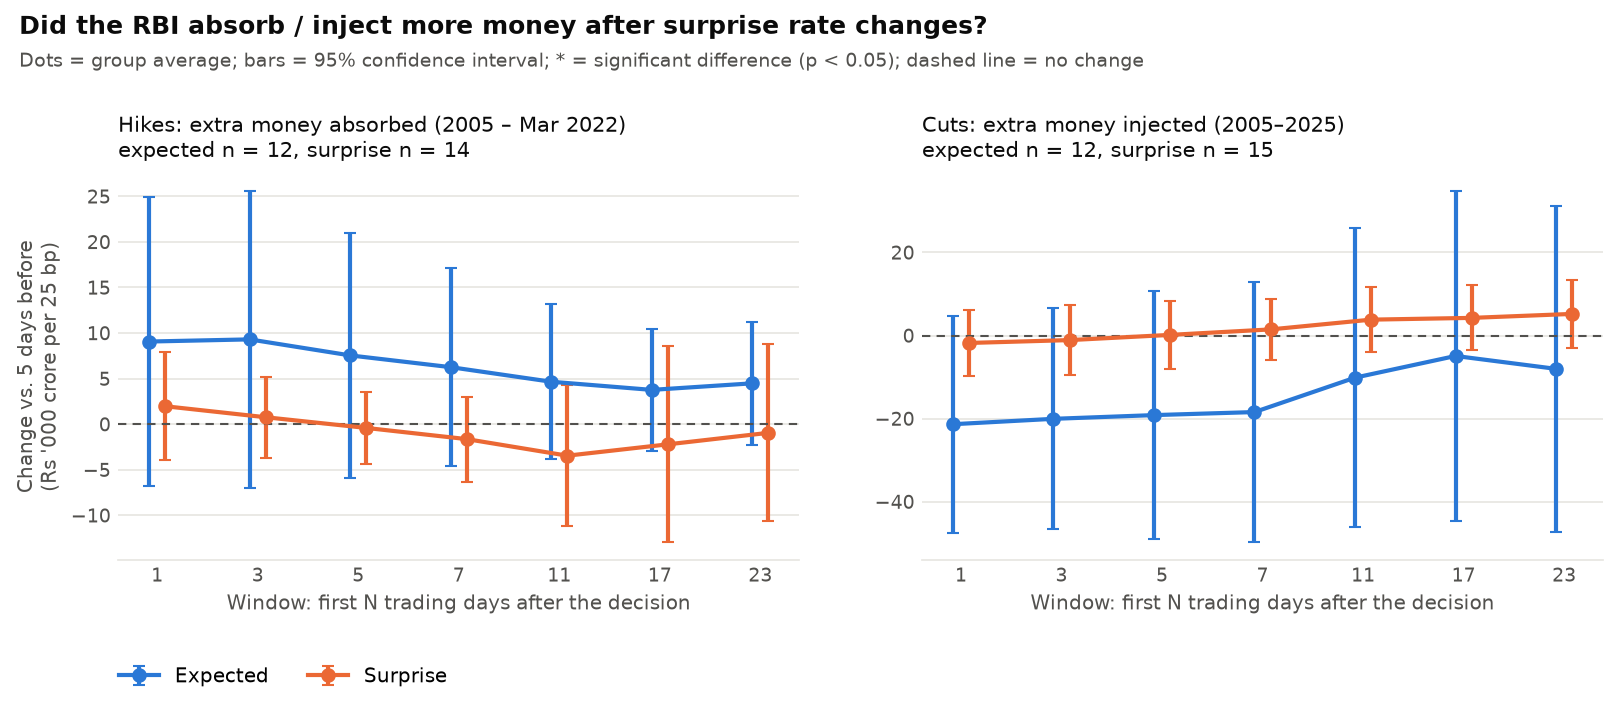

In [ ]:
# ---------- Plot ----------
x = np.arange(len(LAF_WINDOWS))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), dpi=150)

for ax, (name, data) in zip(axes, laf.items()):
    for label, color, shift, name_g in [(1, BLUE, -0.08, "Expected"), (0, ORANGE, 0.08, "Surprise")]:
        g = data.loc[data["expected"] == label, LAF_WINDOWS] / 1e3          # Rs '000 crore
        half = g.sem() * stats.t.ppf(0.975, len(g) - 1)
        ax.errorbar(x + shift, g.mean(), yerr=half, color=color, marker="o", markersize=6,
                    linewidth=2, capsize=3, label=name_g)
    for i, p in enumerate(laf_tables[name]["p_value"]):
        if p < 0.05:
            ax.text(x[i], 0.97, "*", transform=ax.get_xaxis_transform(), ha="center", fontsize=14, color=INK)
    n_e, n_s = int(data["expected"].sum()), int((data["expected"] == 0).sum())
    ax.set_title(f"{name}\nexpected n = {n_e}, surprise n = {n_s}", loc="left", fontsize=10, color=INK, pad=8)
    ax.axhline(0, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.set_xticks(x, [str(n) for n in LAF_WINDOWS])
    ax.set_xlabel("Window: first N trading days after the decision", fontsize=9.5, color=MUTED)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)

axes[0].set_ylabel("Change vs. 5 days before\n(Rs '000 crore per 25 bp)", fontsize=9.5, color=MUTED)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, fontsize=9.5, ncol=2, loc="lower left", bbox_to_anchor=(0.07, -0.01))
fig.suptitle("Did the RBI absorb / inject more money after surprise rate changes?",
             x=0.02, y=0.99, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.text(0.02, 0.915, "Dots = group average; bars = 95% confidence interval; * = significant difference (p < 0.05); dashed line = no change",
         ha="left", fontsize=9, color=MUTED)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.2, top=0.76, wspace=0.18)
plt.show()